<a href="https://colab.research.google.com/github/Dani0601/pm-turi4-clustering-danihidayat/blob/main/TuRi4_Clustering_danihidayat_2488010016.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TuRi 4 — Clustering dengan K-Means (Segmentasi Pelanggan)
**Mata Kuliah:** Pembelajaran Mesin · **Pertemuan 9** · Repo: `pm-turi4-clustering-danihidayat`

Nama: Dani Hidayat &nbsp;&nbsp; NIM: 248010016


## Persiapan: Dataset Pelanggan (data buatan)
Dataset dibuat sintetis dengan seed tetap agar hasil selalu sama. Terdapat 3 kelompok pelanggan tersembunyi (tanpa label).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(42)

def buat_grup(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia': rng.normal(*usia, n).round().clip(18, 70),
        'pendapatan': rng.normal(*pendapatan, n).round(1),   # juta rupiah / tahun
        'skor_belanja': rng.normal(*skor, n).round().clip(1, 100),
    })

df = pd.concat([
    buat_grup(70, (25, 4), (40, 8), (80, 8)),
    buat_grup(65, (45, 5), (120, 12), (25, 8)),
    buat_grup(65, (35, 5), (75, 10), (55, 8)),
], ignore_index=True)

print(df.shape)
df.head()

(200, 3)


,usia,pendapatan,skor_belanja
0,26.0,29.8,83.0
1,21.0,30.9,72.0
2,28.0,32.6,63.0
3,29.0,44.0,82.0
4,18.0,41.1,73.0


In [2]:
df.describe().round(1)

,usia,pendapatan,skor_belanja
count,200.0,200.0,200.0
mean,34.8,77.4,53.5
std,9.4,35.1,23.6
min,18.0,26.2,7.0
25%,27.0,43.4,31.8
50%,34.0,74.2,54.0
75%,42.0,111.7,74.2
max,60.0,141.8,97.0


## Langkah 1 — Menyiapkan data & scaling (wajib)

In [3]:
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)
print('Mean  :', X_scaled.mean(axis=0).round(2))
print('Std   :', X_scaled.std(axis=0).round(2))

Mean  : [-0.  0.  0.]
Std   : [1. 1. 1.]


## Langkah 2 — Metode Elbow menentukan K

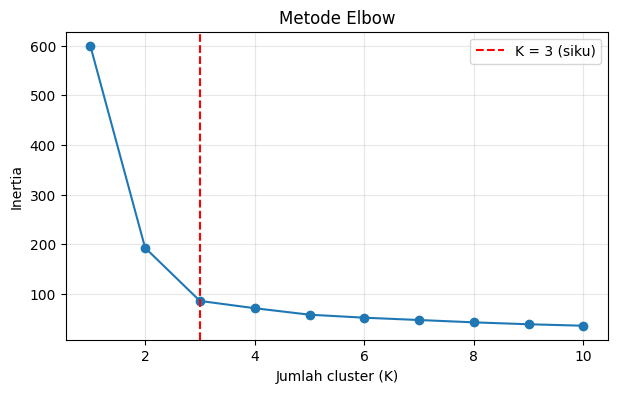

,K,inertia
0,1,600.0
1,2,193.1
2,3,86.2
3,4,71.5
4,5,58.4
5,6,52.4
6,7,47.7
7,8,43.0
8,9,39.2
9,10,36.2


In [4]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(3, color='red', linestyle='--', label='K = 3 (siku)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia')
plt.title('Metode Elbow'); plt.legend(); plt.grid(alpha=.3)
plt.show()

pd.DataFrame({'K': range(1, 11), 'inertia': np.round(inertias, 1)})

## Langkah 3 — Menjalankan K-Means (K=3)

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
2    71
0    65
1    64
Name: count, dtype: int64


## Langkah 4 — Evaluasi silhouette score

In [6]:
sil_k3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette (K=3, scaled):', round(sil_k3, 3))

Silhouette (K=3, scaled): 0.573


## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [7]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
print(profil)

         usia  pendapatan  skor_belanja  jumlah
cluster                                        
0        45.1       120.8          25.3      65
1        34.7        75.6          53.4      64
2        25.3        39.4          79.4      71


In [8]:
# Penamaan cluster otomatis berdasarkan profil (urut pendapatan)
urut = profil['pendapatan'].sort_values().index.tolist()   # rendah -> tinggi
nama = {
    urut[0]: 'Muda Hemat Pendapatan, Gemar Belanja',
    urut[1]: 'Dewasa Menengah, Belanja Moderat',
    urut[2]: 'Mapan Berpendapatan Tinggi, Jarang Belanja',
}
df['segmen'] = df['cluster'].map(nama)
profil['nama_segmen'] = profil.index.map(nama)
profil

,usia,pendapatan,skor_belanja,jumlah,nama_segmen
cluster,,,,,
0,45.1,120.8,25.3,65,"Mapan Berpendapatan Tinggi, Jarang Belanja"
1,34.7,75.6,53.4,64,"Dewasa Menengah, Belanja Moderat"
2,25.3,39.4,79.4,71,"Muda Hemat Pendapatan, Gemar Belanja"


**Penamaan & interpretasi cluster**

| Segmen | Ciri | Saran strategi |
|---|---|---|
| **Muda, pendapatan rendah, skor belanja tinggi** | Usia ±25 th, pendapatan ±39 jt, skor ±79 | Promo/diskon, program cicilan, kampanye media sosial |
| **Dewasa menengah, belanja moderat** | Usia ±35 th, pendapatan ±76 jt, skor ±53 | Program loyalitas, bundling produk |
| **Mapan, pendapatan tinggi, skor belanja rendah** | Usia ±45 th, pendapatan ±121 jt, skor ±25 | Produk premium, personalisasi; potensi belanja belum tergarap |

## Latihan Mandiri

### Latihan 6 — K-Means K=5 vs K=3

In [9]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
lab5 = km5.fit_predict(X_scaled)
sil_k5 = silhouette_score(X_scaled, lab5)
print(f'Silhouette K=3 : {sil_k3:.3f}')
print(f'Silhouette K=5 : {sil_k5:.3f}')

Silhouette K=3 : 0.573
Silhouette K=5 : 0.461


**Jawaban Latihan 6.** Silhouette K=3 (≈0,573) lebih tinggi daripada K=5 (≈0,461). Pada K=5 satu kelompok alami terpecah menjadi beberapa cluster kecil yang saling berdekatan, sehingga jarak antar-cluster mengecil dan cluster kurang terpisah. Jadi **K=3 lebih baik**, selaras dengan hasil Elbow.

### Latihan 7 — K-Means K=3 tanpa scaling

In [10]:
km_ns = KMeans(n_clusters=3, random_state=42, n_init=10)
lab_ns = km_ns.fit_predict(df[['usia','pendapatan','skor_belanja']].values)
sil_ns = silhouette_score(df[['usia','pendapatan','skor_belanja']].values, lab_ns)
print(f'Silhouette dengan scaling   : {sil_k3:.3f}')
print(f'Silhouette tanpa scaling    : {sil_ns:.3f}')

print('\nStd tiap fitur (data asli):')
print(df[['usia','pendapatan','skor_belanja']].std().round(1))

# seberapa mirip pembagian cluster dengan/tanpa scaling
from sklearn.metrics import adjusted_rand_score
print('\nAdjusted Rand Index (scaled vs tanpa scaling):',
      round(adjusted_rand_score(df['cluster'], lab_ns), 3))

Silhouette dengan scaling   : 0.573
Silhouette tanpa scaling    : 0.640

Std tiap fitur (data asli):
usia             9.4
pendapatan      35.1
skor_belanja    23.6
dtype: float64

Adjusted Rand Index (scaled vs tanpa scaling): 0.97


**Jawaban Latihan 7 (kesimpulan).** Nilai silhouette tanpa scaling (≈0,640) ternyata *lebih besar* daripada dengan scaling (≈0,573). Ini **tidak berarti** tanpa scaling lebih baik, karena:

1. Silhouette dihitung pada ruang fitur yang berbeda. Tanpa scaling, jarak hampir seluruhnya ditentukan oleh `pendapatan` (rentang dan variansnya jauh lebih besar dibanding `usia` dan `skor_belanja`), sehingga nilainya tidak sebanding dengan silhouette pada data ter-scaling.
2. Pada data ini ketiga kelompok kebetulan sangat terpisah di sumbu pendapatan, sehingga pembagian oleh pendapatan saja sudah terlihat rapi. Namun `usia` dan `skor_belanja` nyaris tidak berperan, dan hasil ini akan berubah jika satuan fitur berubah (misalnya pendapatan dalam rupiah penuh).

**Kesimpulan:** scaling tetap wajib agar tiap fitur berkontribusi seimbang pada jarak; silhouette hanya bisa dibandingkan secara adil pada ruang fitur yang sama.

### Latihan 8 — Scatter plot cluster: usia (x) vs skor_belanja (y)

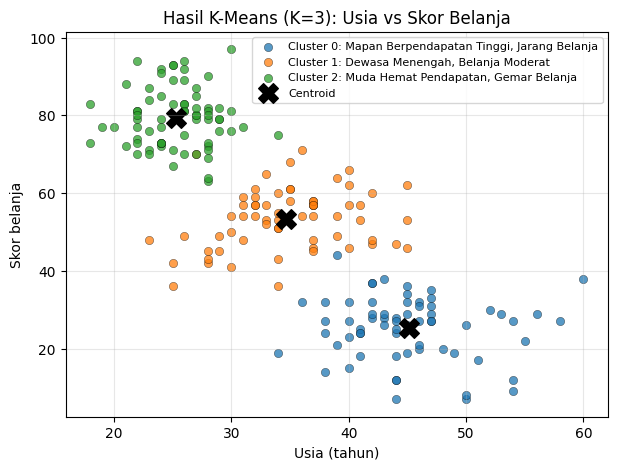

In [11]:
plt.figure(figsize=(7, 5))
for c in sorted(df['cluster'].unique()):
    d = df[df['cluster'] == c]
    plt.scatter(d['usia'], d['skor_belanja'], label=f'Cluster {c}: {nama[c]}', alpha=.75, edgecolor='k', linewidth=.3)

# centroid dikembalikan ke skala asli
pusat = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
plt.scatter(pusat[:, 0], pusat[:, 2], c='black', marker='X', s=200, label='Centroid')
plt.xlabel('Usia (tahun)'); plt.ylabel('Skor belanja')
plt.title('Hasil K-Means (K=3): Usia vs Skor Belanja')
plt.legend(fontsize=8, loc='upper right'); plt.grid(alpha=.3)
plt.show()

**Interpretasi.** Makin muda usia pelanggan, makin tinggi skor belanjanya; ketiga cluster tampak membentuk pita diagonal yang terpisah jelas.

## Refleksi

**9. Bagaimana K-Means menemukan kelompok tanpa label?**

K-Means tidak memakai label, hanya **kemiripan berbasis jarak**. Algoritmanya: (1) tentukan K lalu pilih K centroid awal secara acak (di sklearn dengan k-means++); (2) *assignment* — tiap titik dimasukkan ke centroid terdekat (jarak Euclidean); (3) *update* — centroid dihitung ulang sebagai rata-rata anggota clusternya; (4) ulangi langkah 2–3 sampai penugasan tidak berubah (konvergen). Tujuannya meminimalkan inertia, yaitu jumlah kuadrat jarak titik ke centroid-nya. Dengan begitu titik yang berdekatan otomatis berkumpul dalam satu cluster; makna tiap cluster baru diberikan manusia setelah melihat profilnya.

**10. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**

Inertia selalu turun saat K bertambah. Pada data ini inertia turun tajam dari ≈600 (K=1) ke ≈193 (K=2) dan ≈86 (K=3), lalu hanya turun landai (≈71,5 pada K=4; ≈58 pada K=5, dan seterusnya). Penurunan tajam berhenti di K=3 karena data memang dibangun dari **3 kelompok alami**; K>3 hanya memecah kelompok yang sudah padat sehingga penurunan inertia kecil (*diminishing returns*). Hal ini dikuatkan silhouette tertinggi di K=3 (≈0,573).

**11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**

K-Means berbasis jarak Euclidean, sehingga fitur dengan skala/varians besar mendominasi perhitungan jarak. Pada data ini `pendapatan` (std ≈ 35) jauh lebih besar daripada `usia` (std ≈ 8) dan `skor_belanja` (std ≈ 24), jadi tanpa scaling cluster hampir hanya ditentukan pendapatan dan kontribusi fitur lain terabaikan. Hasilnya bias, bergantung pada satuan (jt vs rupiah), dan nilai evaluasi seperti silhouette tidak sebanding. Dengan `StandardScaler` (mean 0, std 1) semua fitur berkontribusi seimbang.

## Kesimpulan
- Data diskalakan dengan `StandardScaler` sebelum clustering.
- Elbow dan silhouette sama-sama menunjuk **K=3** (silhouette ≈ 0,57), sedangkan K=5 turun menjadi ≈ 0,46.
- Terbentuk 3 segmen pelanggan: muda–hemat tapi gemar belanja, dewasa menengah, serta mapan tapi jarang belanja.
- Scaling wajib; silhouette hanya dapat dibandingkan pada ruang fitur yang sama.